# PBMC3k: Summary of PCA, CAVI, and Gibbs Results

This report summarizes the current CAVI, long-chain Gibbs, and PCA reference results using `X_scaled` and `K=50`. All methods use the same cells, highly variable genes, and downstream settings. ARI/NMI measure clustering agreement only and are not measures of cell-type accuracy.

The current representation uses RSP, L2 norm weighting of loading columns in the current coordinate system, and the first 20 score columns for graph construction. Leiden `resolution` is **0.45**, yielding **9 clusters** for both CAVI and Gibbs. Cluster labels in figures and tables are one-based for display only; the underlying clustering results are unchanged.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score
from IPython.display import Image, display

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)

METHODS = {
    'PCA_scaled': {
        'path': 'PBMC/data/notebook_scaled_pca_baseline.h5ad',
        'cluster': 'leiden_scaled',
        'umap': 'umap_scaled',
        'markers': 'markers_scaled',
    },
    'CAVI': {
        'path': 'PBMC/data/notebook_scaled_scores_d20_leiden9_cavi_gibbs_k50.h5ad',
        'cluster': 'leiden_cavi_scaled_norm_d20_r0p45_k9',
        'umap': 'umap_cavi_scaled_norm_d20',
        'markers': 'markers_cavi_scaled_norm_d20_r0p45_k9',
    },
    'GS': {
        'path': 'PBMC/data/notebook_scaled_scores_d20_leiden9_cavi_gibbs_k50.h5ad',
        'cluster': 'leiden_gibbs_scaled_norm_d20_r0p45_k9',
        'umap': 'umap_gibbs_scaled_norm_d20',
        'markers': 'markers_gibbs_scaled_norm_d20_r0p45_k9',
    },
}
ORDER = ['PCA_scaled', 'CAVI', 'GS']
loaded = {}
adatas = {}
for name, info in METHODS.items():
    if info['path'] not in loaded:
        loaded[info['path']] = sc.read_h5ad(info['path'])
    adatas[name] = loaded[info['path']]
for name in ORDER:
    assert adatas[name].obs[METHODS[name]['cluster']].notna().all()
print({name: adatas[name].shape for name in ORDER})

{'PCA_scaled': (2638, 13714), 'CAVI': (2638, 13714), 'GS': (2638, 13714)}


## 1. Cluster Counts and ARI/NMI

ARI measures agreement in how cells are paired across clusters; NMI (AMI here) measures shared information between two clusterings. Both are invariant to cluster-label permutation and are not classification accuracies.

In [2]:
def labels(method):
    raw = adatas[method].obs[METHODS[method]['cluster']].astype(int)
    return pd.Series((raw + 1).astype(str), index=raw.index, dtype='category')

rows = []
for name in ORDER:
    row = {'Method': name, 'Clusters': labels(name).nunique()}
    for reference in ('PCA_scaled',):
        row[f'ARI vs {reference}'] = adjusted_rand_score(labels(reference), labels(name))
        row[f'NMI vs {reference}'] = adjusted_mutual_info_score(labels(reference), labels(name))
    rows.append(row)
metrics = pd.DataFrame(rows).set_index('Method')
display(metrics.round(4))
print(metrics.round(4).to_string())

,Clusters,ARI vs PCA_scaled,NMI vs PCA_scaled
Method,,,
PCA_scaled,8,1.0000,1.0000
CAVI,9,0.6468,0.8020
GS,9,0.6259,0.7821


            Clusters  ARI vs PCA_scaled  NMI vs PCA_scaled
Method                                                    
PCA_scaled         8             1.0000             1.0000
CAVI               9             0.6468             0.8020
GS                 9             0.6259             0.7821


In [3]:
cluster_sizes = pd.DataFrame({name: labels(name).value_counts().sort_index() for name in ORDER})
cluster_sizes = cluster_sizes.astype('Int64')
cluster_sizes.index.name = 'Cluster'
display(cluster_sizes)
print(cluster_sizes.to_string())

,PCA_scaled,CAVI,GS
Cluster,,,
1,1158,509,306
2,300,632,545
3,343,285,146
4,479,344,349
5,156,445,575
6,159,181,441
7,30,184,202
8,13,15,35
9,<NA>,43,39


         PCA_scaled  CAVI   GS
Cluster                       
1              1158   509  306
2               300   632  545
3               343   285  146
4               479   344  349
5               156   445  575
6               159   181  441
7                30   184  202
8                13    15   35
9              <NA>    43   39


## 2. UMAP Comparison

UMAP is used for visualization only and is not, by itself, evidence that one method is better than another.

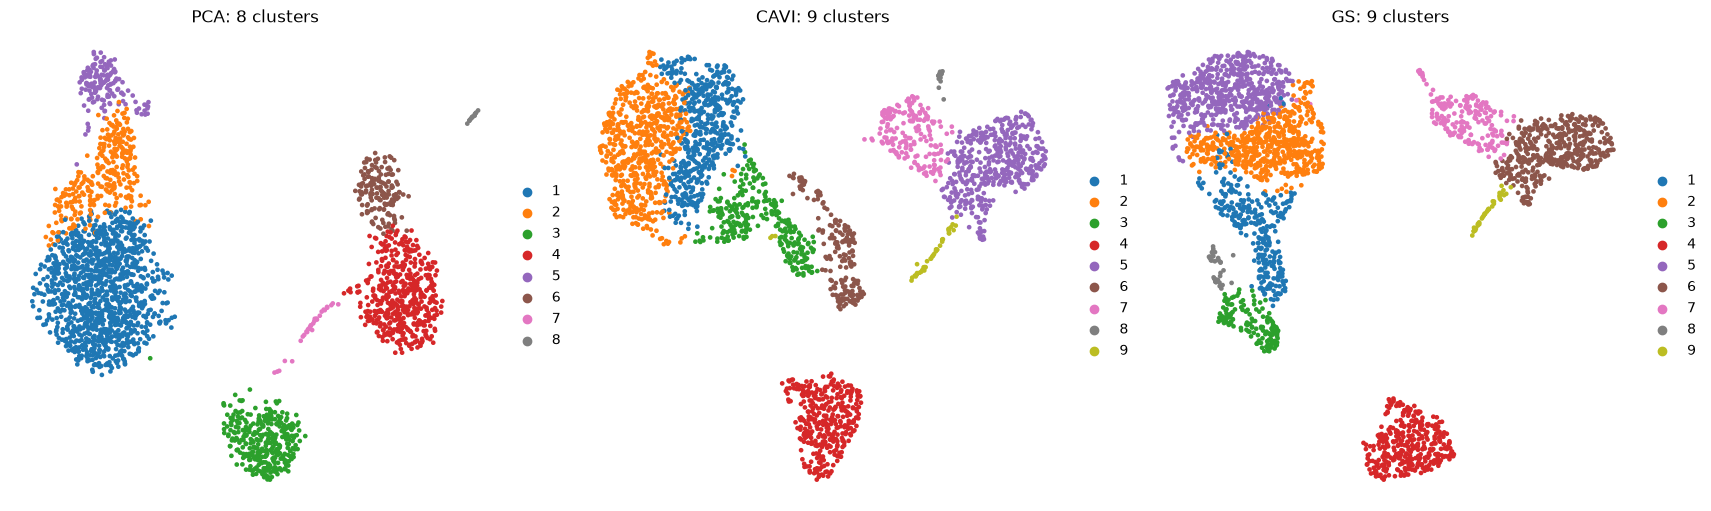

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
for ax, name in zip(axes.ravel(), ORDER):
    info = METHODS[name]
    plot_key = f'_report_label_{name}'
    adatas[name].obs[plot_key] = labels(name)
    method_label = 'PCA' if name == 'PCA_scaled' else name
    sc.pl.embedding(
        adatas[name],
        basis=info['umap'],
        color=plot_key,
        title=f'{method_label}: {labels(name).nunique()} clusters',
        frameon=False,
        show=False,
        ax=ax,
    )
display(fig)
plt.close(fig)

## 3. Top 5 Markers per Cluster

The table reads the Wilcoxon rankings stored in the results, using log-normalized expression across all genes. Cluster labels are shown starting at 1.

In [5]:
marker_rows = []
for name in ORDER:
    result = adatas[name].uns[METHODS[name]['markers']]
    for group in result['names'].dtype.names:
        marker_rows.append({
            'Method': name,
            'Cluster': int(group) + 1,
            'Top 5 markers': ', '.join(map(str, result['names'][group][:5])),
        })
marker_table = pd.DataFrame(marker_rows)
display(marker_table)
print(marker_table.to_string(index=False))

,Method,Cluster,Top 5 markers
0,PCA_scaled,1,"LDHB, RPS12, RPS25, RPS27, RPS6"
1,PCA_scaled,2,"CCL5, NKG7, B2M, GZMA, CST7"
2,PCA_scaled,3,"CD74, CD79A, HLA-DRA, CD79B, HLA-DPB1"
3,PCA_scaled,4,"LYZ, S100A9, S100A8, TYROBP, FTL"
4,PCA_scaled,5,"NKG7, GNLY, GZMB, CTSW, PRF1"
5,PCA_scaled,6,"LST1, FCER1G, AIF1, FCGR3A, COTL1"
6,PCA_scaled,7,"HLA-DPA1, HLA-DPB1, HLA-DRB1, HLA-DRA, CD74"
7,PCA_scaled,8,"PF4, SDPR, GNG11, PPBP, NRGN"
8,CAVI,1,"LTB, IL32, LDHB, CD3D, IL7R"
9,CAVI,2,"RPL32, RPS12, RPS6, RPS27, RPS14"


    Method  Cluster                               Top 5 markers
PCA_scaled        1             LDHB, RPS12, RPS25, RPS27, RPS6
PCA_scaled        2                 CCL5, NKG7, B2M, GZMA, CST7
PCA_scaled        3       CD74, CD79A, HLA-DRA, CD79B, HLA-DPB1
PCA_scaled        4            LYZ, S100A9, S100A8, TYROBP, FTL
PCA_scaled        5                NKG7, GNLY, GZMB, CTSW, PRF1
PCA_scaled        6           LST1, FCER1G, AIF1, FCGR3A, COTL1
PCA_scaled        7 HLA-DPA1, HLA-DPB1, HLA-DRB1, HLA-DRA, CD74
PCA_scaled        8                PF4, SDPR, GNG11, PPBP, NRGN
      CAVI        1                 LTB, IL32, LDHB, CD3D, IL7R
      CAVI        2            RPL32, RPS12, RPS6, RPS27, RPS14
      CAVI        3                 CCL5, NKG7, GZMA, B2M, CST7
      CAVI        4       CD74, CD79A, HLA-DRA, CD79B, HLA-DPB1
      CAVI        5           S100A9, LYZ, S100A8, TYROBP, FCN1
      CAVI        6                NKG7, CTSW, CST7, GNLY, GZMA
      CAVI        7           LST1, FCER

## 4. Runtime and Sampling Diagnostics

CAVI uses the ELBO stopping criterion, whereas Gibbs uses a single sampling chain. Entries with low ESS still require caution: neither a long chain nor stable clustering proves that the full posterior has been adequately explored.

In [6]:
cavi_d = adatas['CAVI'].uns['cavi_scaled_norm_d10']['diagnostics']
gs_d = adatas['GS'].uns['gibbs_scaled_norm_d10']['diagnostics']
leiden9 = adatas['CAVI'].uns['leiden9_d20']['selected']
active_mask = gs_d['active_mask'].astype(bool)
active_ess_median = float(np.median(gs_d['sampling']['bulk_B'][active_mask]))
cavi_active20 = int(cavi_d['active_mask'][:, :20].any(axis=0).sum())
gs_active20 = int(gs_d['active_mask'][:, :20].any(axis=0).sum())
diagnostics = pd.DataFrame([
    ('Input', 'X_scaled', 'X_scaled'),
    ('K', 50, 50),
    ('RSP status', cavi_d['rsp']['status_code'], gs_d['rsp']['status_code']),
    ('Score weighting', cavi_d['score_weighting'], gs_d['score_weighting']),
    ('Report columns', 20, 20),
    ('Leiden resolution', leiden9['cavi']['resolution'], leiden9['gibbs']['resolution']),
    ('Report clusters', labels('CAVI').nunique(), labels('GS').nunique()),
    ('Fit sweeps', cavi_d['fit']['n_iter'], gs_d['fit']['n_iter']),
    ('Burn-in', '—', gs_d['fit']['burn_in']),
    ('Thin', '—', gs_d['fit']['thin']),
    ('Kept draws', '—', gs_d['fit']['n_kept']),
    ('Converged / Gamma', f"{cavi_d['fit']['converged']} / {cavi_d['fit']['stop_reason']}", gs_d['fit']['gamma_mode']),
    ('Active factors (full)', cavi_d['active_factor_count'], gs_d['active_factor_count']),
    ('Active factors (first 20)', cavi_active20, gs_active20),
    ('Median bulk ESS (active loadings)', '—', round(active_ess_median, 2)),
    ('Minimum bulk ESS (loadings)', '—', round(gs_d['sampling']['bulk_summary']['B']['min'], 2)),
    ('Minimum bulk ESS (noise variances)', '—', round(gs_d['sampling']['bulk_summary']['sigma2']['min'], 2)),
    ('Review required', '—', gs_d['sampling']['review_required']),
], columns=['Item', 'CAVI', 'GS'])
display(diagnostics)
print(diagnostics.to_string(index=False))

,Item,CAVI,GS
0,Input,X_scaled,X_scaled
1,K,50,50
2,RSP status,1,1
3,Score weighting,loading_column_l2_norm,loading_column_l2_norm
4,Report columns,20,20
5,Leiden resolution,0.45,0.45
6,Report clusters,9,9
7,Fit sweeps,465,20000
8,Burn-in,—,10000
9,Thin,—,10


                              Item                   CAVI                     GS
                             Input               X_scaled               X_scaled
                                 K                     50                     50
                        RSP status                      1                      1
                   Score weighting loading_column_l2_norm loading_column_l2_norm
                    Report columns                     20                     20
                 Leiden resolution                   0.45                   0.45
                   Report clusters                      9                      9
                        Fit sweeps                    465                  20000
                           Burn-in                      —                  10000
                              Thin                      —                     10
                        Kept draws                      —                   1000
                 Converged /

## 5. Loading Column Norms Before and After RSP

For CAVI, `mu_` is compared with `mu_aligned_`; for Gibbs, the posterior mean loadings are compared before and after RSP alignment. The plots show the L2 norm of each loading column and help inspect the aligned factor representation.

CAVI


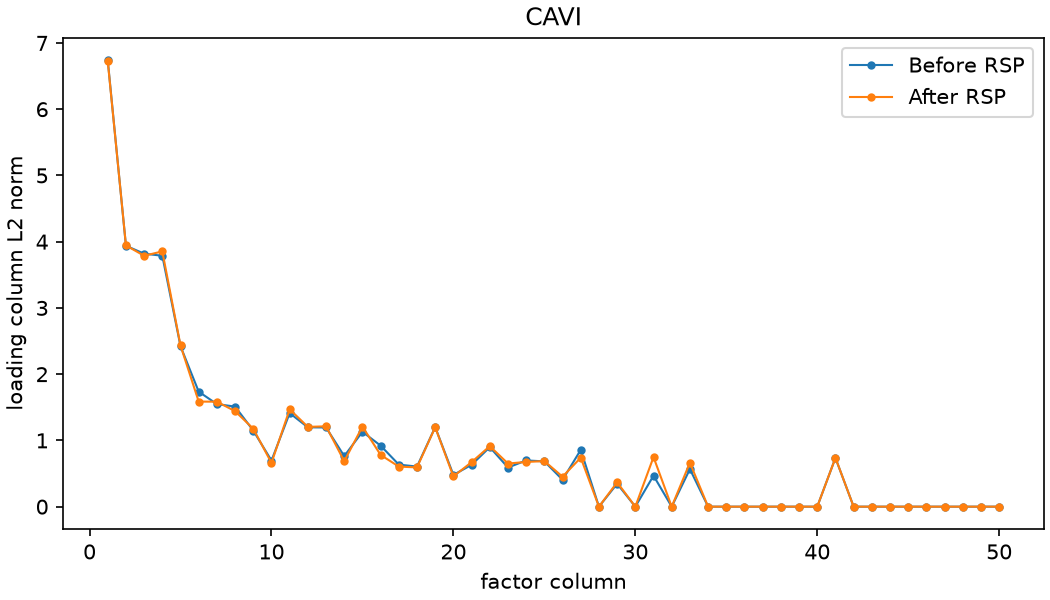

GS


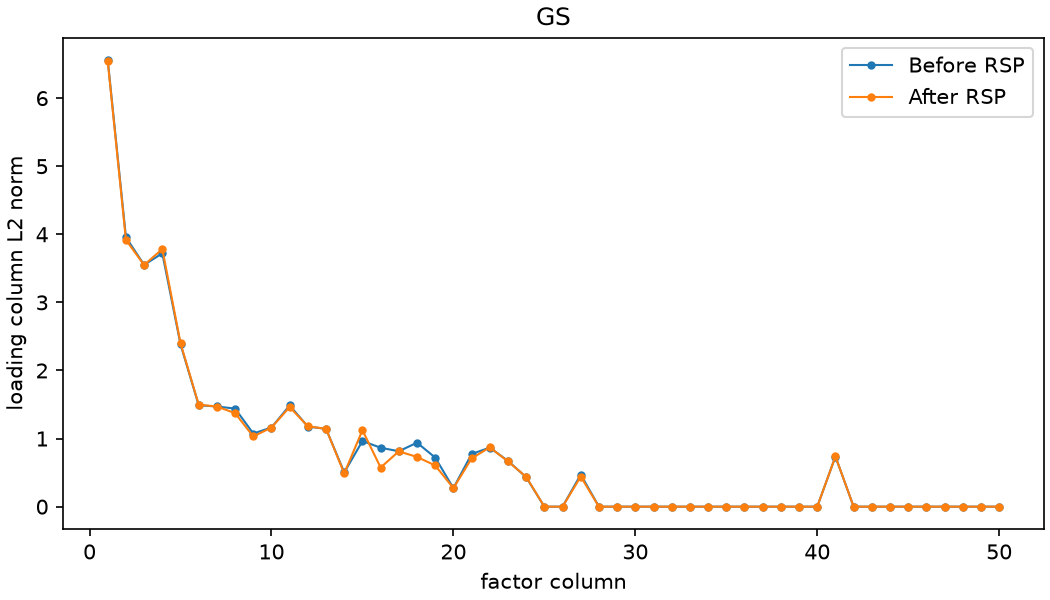

In [7]:
rsp_figures = {
    'CAVI': 'PBMC/figures/notebook_scaled_cavi_norm_d10_k50/loading_column_norms_cavi_scaled_norm_d10.png',
    'GS': 'PBMC/figures/notebook_scaled_gibbs_norm_d10_n20000_b10000_t10_k50/loading_column_norms_gibbs_scaled_norm_d10.png',
}
for name, path in rsp_figures.items():
    assert Path(path).is_file(), path
    print(name)
    display(Image(filename=path))

## 6. Conclusions

The current workflow uses **X_scaled + RSP + loading-column norm weighting + the first 20 score columns + Leiden resolution 0.45**. CAVI and Gibbs both produce 9 clusters, with ARI **0.8844** and AMI **0.9062** between them; the `PCA_scaled` reference has 8 clusters. The target of nine clusters was obtained by tuning the resolution with the representation fixed and should not be interpreted as the true number of cell types or as a biologically optimal result.

Further assessment should continue to use established biological markers, rare cell populations, and stability across Leiden seeds and subsampling. Gibbs has `review_required=True`, and some entries still have low ESS; the long chain does not prove that the full posterior has been adequately explored.

Result files:

- PCA: `PBMC/data/notebook_scaled_pca_baseline.h5ad`
- Current 9-cluster CAVI and Gibbs results: `PBMC/data/notebook_scaled_scores_d20_leiden9_cavi_gibbs_k50.h5ad`
- Current UMAP comparison: `PBMC/figures/notebook_scaled_clustering_cavi_vs_gibbs_d20_leiden9_k50.png`